In [28]:
# First install the extendedjetpy package with: python setup.py install
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import JetCode # CHANGE TO extendedjetpy CUANDO ANDE BIEN!!!!
import time

In [29]:
# Define the SED function
def model_sed(E, sigma0, Lj, a_inj):
    #CAMBIARLO A keyword arguments! Menos chances de errores
    """
    Total (synchrotron + SSC) SED calculated at photon energies in the vector E.
    The available free parameters are: 
    - sigma0 (initial magnetization) 
    - Lj (jet luminosity)
    - a_inj (power injected as Q(z) \propto z^-a_inj)
    """
    # CHANGE TO extendedjetpy CUANDO ANDE BIEN!!!!
    
    # This routine returns m_data_max values, as defined in global.f90
    fit_values = JetCode.sed_model(sigma0, Lj, z0, a_inj, E, z) 
    
    # The only useful values are the first ones up to the number of points in E
    return( fit_values[:len(E)]) 

def model_syn(E, sigma0, Lj, a_inj):
    #CAMBIARLO A keyword arguments! Menos chances de errores
    """
    Total synchrotron SED calculated at photon energies in the vector E.
    The available free parameters are: 
    - sigma0 (initial magnetization) 
    - Lj (jet luminosity)
    - a_inj (power injected as Q(z) \propto z^-(1+a_inj) )
    """
    # CHANGE TO extendedjetpy CUANDO ANDE BIEN!!!!
    
    # This routine returns m_data_max values, as defined in global.f90
    fit_values = JetCode.syn_model(sigma0, Lj, a_inj, E) 
    
    # The only useful values are the first ones up to the number of points in E
    return( fit_values[:len(E)])       

In [30]:
# Sthetics for plots
nice_fonts = {
    # Use LaTeX to write all text
    "text.usetex": True,
    "font.family": 'serif',
    # Use 10pt font in plots, to match 10pt font in the document
    "axes.labelsize": 18,
    "font.size": 20,
    "axes.linewidth": 1.5,
    "axes.titlesize": 16,
    # Make the legend/label fonts a little smaller
    "legend.fontsize": 14,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "xtick.major.size": 5.5,  # major tick size in points
    "xtick.minor.size": 4,    # minor tick size in points
    "ytick.major.size": 5.5,  # major tick size in points
    "ytick.minor.size": 3.5,  # minor tick size in points
    "xtick.major.width": 1.4,  # major tick width in points
    "xtick.minor.width": 1.3,  # minor tick width in points
    "ytick.major.width": 1.4,  # major tick width in points
    "ytick.minor.width": 1.3,  # minor tick width in points
}
matplotlib.rcParams.update(nice_fonts)

In [31]:
#Constants
mJy = 1.0e-26
dist = 16.8*3.0856e24  # Distance to the source = 16.8 Mpc
h = 6.6260755e-27      # erg s
eV = 1.602176e-12      # eV to erg
a = 4.0*np.pi*dist**2  # Flux dilution factor
M_BH = 6.5e9           # Black hole mass [Msun] (EHT+2018?)
R_g = 1.477e5*M_BH     # Gravitational radius (M_BH [Msun])

# Default model parameters
sigma0_def = 1e1
Lj_def = 1e43
z0_def = 10.0*R_g
a_inj_def = 0.5

# Define the energy range for the SED
E_min = 4e-7 * eV #A 3.3e-7 is prox 100 MHz
E_max = 2e7 * eV
n_points = 80
E = np.geomspace(E_min, E_max, n_points)
z = np.geomspace(5*R_g, 100*R_g, n_points)

# Explore sigma0 variations

In [32]:
# Make a list with the values of sigma0
sigma0s = [1e0, 2e0, 4e0, 30e0] 

# Calculate the SED for each sigma0 value (fixing default parameters)
SEDs = []
for sigma0 in sigma0s:
    print(f'{sigma0=}')
    time.sleep(1)
    #SED = model_sed(E, z, sigma0, Lj_def, z0_def, a_inj_def)
    SED = model_syn(E, sigma0, Lj_def, a_inj_def)
    time.sleep(2)
    SEDs.append(SED)

sigma0=1.0
sigma0=2.0
sigma0=3.0
sigma0=30.0


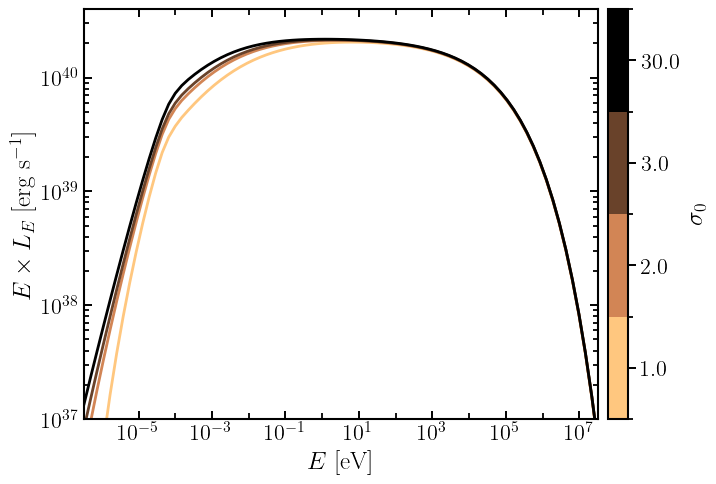

In [34]:
# === Figure setup ===
fig, ax = plt.subplots(figsize=(8, 5))

# === Discrete colormap ===
n = len(sigma0s)
cmap = matplotlib.colormaps['copper_r'].resampled(n)
colors = cmap(np.linspace(0, 1, n))

# Discrete colorbar setup
bounds = np.arange(0.5, n + 1.5)
norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# === Plot parameters ===
xmin, xmax = E_min / eV, E_max / eV
ymin, ymax = 1e37, 4e40

# === Plot SED curves ===
for i in range(n):
    ax.plot(E/eV, E * SEDs[i] * a, color=colors[i], lw=2, label='')

# === Scales and limits ===
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# === Labels ===
ax.set_xlabel(r"$E$ [eV]")
ax.set_ylabel(r"$E \times L_E$ [erg s$^{-1}$]")

# === Colorbar ===
cbar = fig.colorbar(sm, ticks=np.arange(1, n + 1), pad=0.015, ax=ax)
cbar.ax.set_yticklabels(sigma0s)
cbar.set_label(r"$\sigma_0$")

# === Custom tick positions ===
major_ticks = [1e-5, 1e-3, 1e-1, 1e1, 1e3, 1e5, 1e7]
minor_ticks = [1e-4, 1e-2, 1e0, 1e2, 1e4, 1e6]

# Set manually and label only the major ticks
ax.set_xscale('log')
ax.xaxis.set_major_locator(mticker.FixedLocator(major_ticks))
ax.xaxis.set_minor_locator(mticker.FixedLocator(minor_ticks))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())

ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.tick_params(direction='in', which='both', right=True, top=True)

# === Legend ===
#ax.legend(frameon=False, fontsize=10, loc='best')

# === Layout and save ===
fig.tight_layout(pad=0.2)
fig.subplots_adjust(bottom=0.15, top=0.97, left=0.14, right=0.91)
fig.savefig('SEDs_sigma0s.pdf', bbox_inches='tight', pad_inches=0.01)
plt.show()

# Explore Ljet variations

In [35]:
# Make a list with the values of Lj 
Ljs = [1e42, 3e42, 1e43, 3e43, 1e44] 

# Calculate the SED for each Lj (fixing default parameters)
SEDs = []
for Lj in Ljs:
    print(f'{Lj=}')
    SED = model_syn(E, sigma0_def, Lj, a_inj_def)
    time.sleep(2)
    SEDs.append(SED)

Lj=1e+42
Lj=3e+42
Lj=1e+43
Lj=3e+43
Lj=1e+44


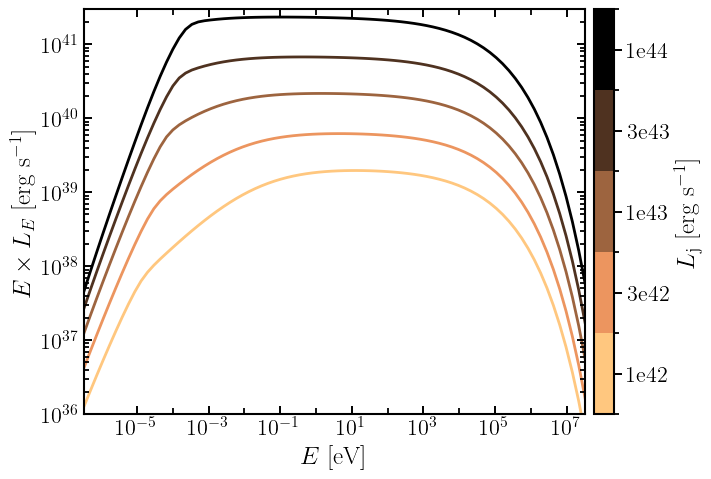

In [44]:
# === Plot data and model ===
fig, ax = plt.subplots(figsize=(8,5))

# === Discrete colormap ===
n = len(Ljs)
cmap = matplotlib.colormaps['copper_r'].resampled(n)
colors = cmap(np.linspace(0, 1, n))

# Discrete colorbar setup
bounds = np.arange(0.5, n + 1.5)
norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# === Axis labels ===
ax.set_xlabel(r"$E$ [eV]")
ax.set_ylabel(r"$E \times L_E$ [erg s$^{-1}$]")

# === Axis limits ===
xmin, xmax = E_min/eV, E_max/eV
ax.set_xlim(xmin, xmax)
ax.set_ylim(1e36, 3e41)

# === Plot individual SEDs ===
for i in range(n):
    ax.plot(E/eV, E * SEDs[i] * a, ls='-', color=colors[i], lw=2, zorder=1)

ax.set_xscale('log')
ax.set_yscale('log')

# === Discrete colorbar ===
cbar = fig.colorbar(sm, ticks=c, label=r"$L_\mathrm{j}$ [erg s$^{-1}$]", pad=0.015, ax=ax)
cbar.ax.set_yticklabels([f"{Lj:.0e}".replace("+0", "").replace("+", "") for Lj in Ljs])

# === Custom x-ticks ===
major_ticks = [1e-5, 1e-3, 1e-1, 1e1, 1e3, 1e5, 1e7]
minor_ticks = [1e-4, 1e-2, 1e0, 1e2, 1e4, 1e6]

ax.xaxis.set_major_locator(mticker.FixedLocator(major_ticks))
ax.xaxis.set_minor_locator(mticker.FixedLocator(minor_ticks))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())

ax.tick_params(direction='in', which='both', right=True, top=True)

# === Legend and layout ===
ax.legend([], frameon=False)
fig.subplots_adjust(bottom=0.16, top=0.97, left=0.14, right=0.89)

# === Save and show ===
fig.savefig('SEDs_Ljs.pdf', bbox_inches='tight', pad_inches=0)
plt.show()

# Explore a_inj variations

In [45]:
# Make a list with the values of a_inj 
a_injs = [0.01, 0.5, 0.99, 1.5] 
a_inj_labels = [0.0, 0.5, 1.0, 1.5] 

# Calculate the SED for each a_inj (fixing default parameters)
SEDs = []
for a_inj in a_injs:
    print(f'{a_inj=}')
    time.sleep(1)
    #SED = model_sed(E, z, sigma0, Lj, z0, a_inj)
    SED = model_syn(E, sigma0_def, Lj_def, a_inj)
    time.sleep(2)
    SEDs.append(SED)

a_inj=0.01
a_inj=0.5
a_inj=0.99
a_inj=1.5


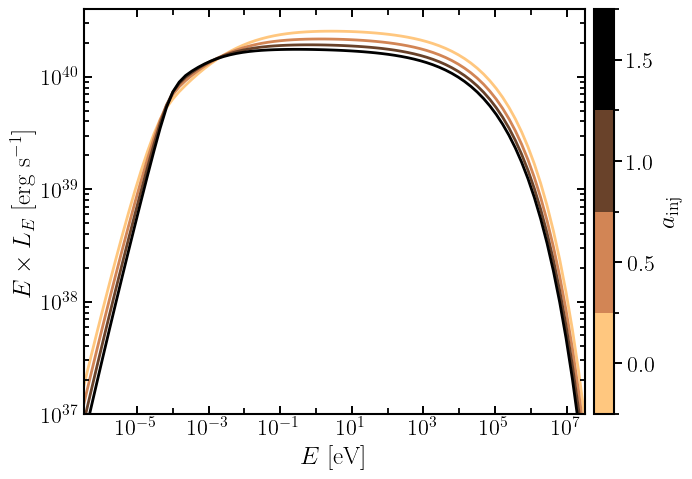

In [51]:
# === Plot data and model ===
fig, ax = plt.subplots(figsize=(8,5))

# === Discrete colormap ===
n = len(a_injs)
cmap = matplotlib.colormaps['copper_r'].resampled(n)
colors = cmap(np.linspace(0, 1, n))

# Discrete colorbar setup
bounds = np.arange(0.5, n + 1.5)
norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# === Axis labels ===
ax.set_xlabel(r"$E$ [eV]")
ax.set_ylabel(r"$E \times L_E$ [erg s$^{-1}$]")

# === Axis limits ===
xmin, xmax = E_min/eV, E_max/eV
ax.set_xlim(xmin, xmax)
ax.set_ylim(1e37, 4e40)

# === Plot individual SEDs ===
for i in range(n):
    ax.plot(E/eV, E * SEDs[i] * a, ls='-', color=colors[i], lw=2, zorder=1)

ax.set_xscale('log')
ax.set_yscale('log')

# === Discrete colorbar ===
cbar = fig.colorbar(sm, ticks=c, label=r"$a_\mathrm{inj}$", pad=0.015, ax=ax)
cbar.ax.set_yticklabels(a_inj_labels)  # vertically oriented colorbar

# === Custom x-ticks ===
major_ticks = [1e-5, 1e-3, 1e-1, 1e1, 1e3, 1e5, 1e7]
minor_ticks = [1e-4, 1e-2, 1e0, 1e2, 1e4, 1e6]

ax.xaxis.set_major_locator(mticker.FixedLocator(major_ticks))
ax.xaxis.set_minor_locator(mticker.FixedLocator(minor_ticks))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())

ax.tick_params(direction='in', which='both', right=True, top=True)

# === Legend and layout ===
ax.legend([], frameon=False)
fig.subplots_adjust(bottom=0.16, top=0.97, left=0.14, right=0.89)

# === Save and show ===
fig.savefig('SEDs_a_injs.pdf')
plt.show()